# Case A SMT example models

This figure is to show the effect of partial stripping on the WR phase.

In [1]:
# Open Zsun, 0.45, 0.1 Zsun grids

from posydon.grids.psygrid import PSyGrid
from posydon.config import PATH_TO_POSYDON_DATA
from posydon.utils.common_functions import convert_metallicity_to_string, orbital_separation_from_period
from posydon.popsyn.distributions import PowerLawPeriod
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cmap import Colormap
import pickle
from pathlib import Path
from tqdm import tqdm
from scipy.stats import gaussian_kde
from wr_population.optical_depth import optical_depth_calculation
from wr_population.classification import classify_WR
from wr_population.paths import FIGURE_DIR

tol_vibrant = Colormap('tol:vibrant')(np.linspace(0, 1, 7))

grid_Zsun = PSyGrid(f"{PATH_TO_POSYDON_DATA}/HMS-HMS/1e+00_Zsun.h5")
grid_045Zsun = PSyGrid(f"{PATH_TO_POSYDON_DATA}/HMS-HMS/4.5e-01_Zsun.h5")
grid_01Zsun = PSyGrid(f"{PATH_TO_POSYDON_DATA}/HMS-HMS/1e-01_Zsun.h5")

from wr_population.plotting import use_posydon_style
use_posydon_style()


In [2]:
period_value =  1.00000000e+01 # days
M1_value = 44.77441597 # Msun
q_value = 0.8 # M2/M1
M2_value = M1_value * q_value

print(f"Period: {period_value} days, M1: {M1_value} Msun, M2: {M2_value} Msun")

Period: 10.0 days, M1: 44.77441597 Msun, M2: 35.819532776 Msun


In [3]:
# in Zsun find the closest model to the given period, M1, and M2

Zsun_data = grid_Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# print(np.unique(Zsun_data['period_days']))
# print(np.unique(Zsun_data['star_1_mass']))
# print(np.unique(Zsun_data['star_2_mass']))


# Find the closest model in Zsun grid
P_mask = np.isclose(Zsun_data['period_days'], period_value, atol=0.1)
M1_mask = np.isclose(Zsun_data['star_1_mass'], M1_value, atol=1)
M2_mask = np.isclose(Zsun_data['star_2_mass'], M2_value, atol=1)

model_id = np.where(P_mask & M1_mask & M2_mask)[0][0]
Zsun_model = grid_Zsun[model_id]

Zsun045_data = grid_045Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.45 Zsun grid
P_mask_045 = np.isclose(Zsun045_data['period_days'], period_value, atol=0.1)
M1_mask_045 = np.isclose(Zsun045_data['star_1_mass'], M1_value, atol=1)
M2_mask_045 = np.isclose(Zsun045_data['star_2_mass'], M2_value, atol=1)

model_id_045 = np.where(P_mask_045 & M1_mask_045 & M2_mask_045)[0][0]
Zsun045_model = grid_045Zsun[model_id_045]

# 01 Zsun data
Zsun01_data = grid_01Zsun.initial_values[['period_days', "star_1_mass", "star_2_mass"]]
# Find the closest model in 0.1 Zsun grid
P_mask_01 = np.isclose(Zsun01_data['period_days'], period_value, atol=0.1)
M1_mask_01 = np.isclose( Zsun01_data['star_1_mass'], M1_value, atol=1)
M2_mask_01 = np.isclose( Zsun01_data['star_2_mass'], M2_value, atol=1)

model_id_01 = np.where(P_mask_01 & M1_mask_01 & M2_mask_01)[0][0]
Zsun01_model = grid_01Zsun[model_id_01]


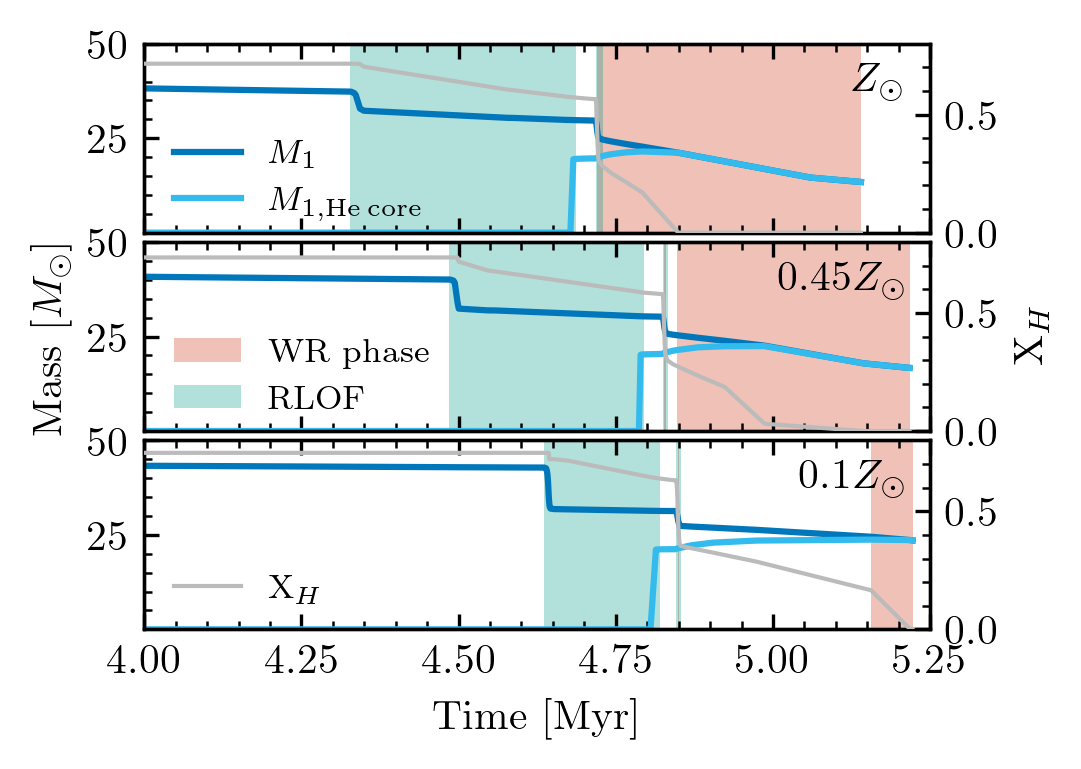

In [4]:

# plot the evolution of the model

fig, axes = plt.subplots(3, 1, figsize=(3.38, 2.535))

axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[0].plot(Zsun_model.binary_history['age']/1e6, Zsun_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[1].plot(Zsun045_model.binary_history['age']/1e6, Zsun045_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])

axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.binary_history['star_1_mass'], label=r'$M_1$', color=tol_vibrant[0])
axes[2].plot(Zsun01_model.binary_history['age']/1e6, Zsun01_model.history1['he_core_mass'], label=r'$M_{1,\mathrm{He\, core}}$', color=tol_vibrant[1])


labels = ['Zsun', '0.45Zsun', '0.1Zsun']
# calculate the optical depth for each model
optical_depth = {}
for model, label in zip([Zsun_model, Zsun045_model, Zsun01_model], labels):
    optical_depth[label] = optical_depth_calculation(M=model.binary_history['star_1_mass'],
                                                                      R=10**model.history1['log_R'],
                                                                      L=10**model.history1['log_L'],
                                                                      Mdot=10**model.binary_history['lg_mstar_dot_1'],
                                                                      surface_H=model.history1['surface_h1'],
                                                                      surface_He=model.history1['surface_he4'],
                                                                      Teff = 10**model.history1['log_Teff'],)


for i, model in enumerate([Zsun_model, Zsun045_model, Zsun01_model]):
    # WNE, WNL, WC masks

    # the grid tracks have no star state, so core-H burning WNL stars are not excluded here
    WNL, WNE, WC = classify_WR({'surface_H': model.history1['surface_h1'],
                                'surface_He': model.history1['surface_he4'],
                                'optical_depth': optical_depth[list(optical_depth.keys())[i]]},
                               exclude_H_burning=False)

    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(WNL | WNE | WC), color=tol_vibrant[4], alpha=0.3, label='WR phase',edgecolor=None )
    # calculate WR durattion
    if np.any(WNL | WNE | WC):
        WR_duration = model.binary_history['age'][WNL | WNE | WC][-1] - model.binary_history['age'][WNL | WNE | WC][0]
    else: 
        WR_duration = 0
    
    axes[i].set_ylim(0.0001, 50)
    axes[i].set_xlim(4, 5.25)
    
    start_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.05)[0]
    final_id = np.where(model.binary_history['rl_relative_overflow_1'] > -0.01)[0][-1]
    
    axes[i].fill_between(model.binary_history['age']/1e6, 0, 50, where=(model.binary_history['rl_relative_overflow_1'] > -0.01), color=tol_vibrant[2], alpha=0.3, label='RLOF', edgecolor=None)
    
    # plot a second y-axis for surface hydrogen abundance
    ax2 = axes[i].twinx()
    ax2.plot(model.binary_history['age']/1e6, model.history1['surface_h1'], color=tol_vibrant[6], zorder=5, label=r'$\mathrm{X}_H$', lw=1)
    if i == 1:
        ax2.set_ylabel(r'$\mathrm{X}_H$')
    ax2.set_ylim(0, 0.8)

# build 2 legends
# legend 1 in axes[0]: M1 and He Core only
handles0, labels0 = axes[0].get_legend_handles_labels()
filtered0 = [(h, l) for h, l in zip(handles0, labels0) if l in [r'$M_1$', r'$M_{1,\mathrm{He\, core}}$']]
axes[0].legend([h for h, l in filtered0], [l for h, l in filtered0],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

# legend 2 in axes[1]: WR phase and RLOF only
handles1, labels1 = axes[1].get_legend_handles_labels()
filtered1 = [(h, l) for h, l in zip(handles1, labels1) if l in ['WR phase', 'RLOF']]
axes[1].legend([h for h, l in filtered1], [l for h, l in filtered1],
               bbox_to_anchor=(0.0, 0.65), loc='upper left', ncol=1)

handles2, labels2 = ax2.get_legend_handles_labels()
filtered2 = [(h, l) for h, l in zip(handles2, labels2) if l in [r'$\mathrm{X}_H$']]
axes[2].legend([h for h, l in filtered2], [l for h, l in filtered2], 
               bbox_to_anchor=(0.0, 0.45), loc='upper left', ncol=1)


plt.subplots_adjust(hspace=0.05)

axes[0].set_xticklabels([])
axes[1].set_xticklabels([])
    
axes[1].set_ylabel('Mass [$M_\odot$]')
axes[2].set_xlabel('Time [Myr]')

axes[0].text(0.97, 0.75, '$Z_\odot$', transform=axes[0].transAxes, ha='right')
axes[1].text(0.97, 0.75, '$0.45 Z_\odot$', transform=axes[1].transAxes, ha='right')
axes[2].text(0.97, 0.75, '$0.1 Z_\odot$', transform=axes[2].transAxes, ha='right')

figure_folder = FIGURE_DIR

plt.savefig(f"{figure_folder}/png/Case_A_WR_evolution_Zsun_045Zsun_01Zsun.png", dpi=300, bbox_inches='tight')
plt.savefig(f"{figure_folder}/pdf/Case_A_WR_evolution_Zsun_045Zsun_01Zsun.pdf", dpi=300, bbox_inches='tight')
plt.show()